# Phase 2 – Notebook 2: Deep Learning Model (MLP with Embeddings)

**What this notebook does (in simple words):**
1. Prepares the data for a neural network.
2. Builds a small PyTorch network (an MLP) that learns **embeddings** for airline, origin and destination.
3. Trains it with dropout, weight decay, class weights and early stopping.
4. Tests it on the test set and compares it with the ML baselines from Notebook 1.

**Deep learning ideas used here:**
- **Embeddings:** each airline / airport gets a few numbers that the network learns by itself.
- **Dropout:** randomly switches off some neurons while training, so the network cannot just memorize.
- **Weight decay:** a small penalty on large weights, also against memorizing.
- **BatchNorm:** keeps the numbers inside the network on a stable scale, so training is smoother.
- **Class weight (pos_weight):** delayed flights are rare (about 25%), so mistakes on them count more.
- **Early stopping:** we stop training when the validation score stops improving, and keep the best version.

In [1]:
import sys, os, time
from pathlib import Path

# Work from the project root so imports and paths always work
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("Project root:", ROOT)
print("PyTorch version:", torch.__version__)

Project root: /Users/atharvatiwari/Desktop/flight-delay-prediction
PyTorch version: 2.15.0


## 1. Load data and split by time
Same data, same features and same split as Notebook 1: 70% train, 15% validation, 15% test, in time order.

In [2]:
from src.data_loader import load_data
from src.preprocessing import clean_data, create_target
from src.phase2_history_features import add_history_features, PHASE2_NUMERIC_FEATURES

df_p2, _ = add_history_features(create_target(clean_data(load_data())), train_ratio=0.70)

n = len(df_p2)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_df = df_p2.iloc[:train_end].copy()
val_df   = df_p2.iloc[train_end:val_end].copy()
test_df  = df_p2.iloc[val_end:].copy()

y_val, y_test = val_df["delayed"].values, test_df["delayed"].values
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print("Number of numeric features:", len(PHASE2_NUMERIC_FEATURES))

Train: 229,142 | Validation: 49,102 | Test: 49,102
Number of numeric features: 20


## 2. How the network sees the data
- Text columns (`carrier`, `origin`, `dest`) are turned into **whole-number IDs**. An extra ID is kept for unseen values (out-of-vocabulary).
- The 20 numeric features are **standardized**. The scaler learns its mean and spread from the **training data only**.

In [3]:
from src.dl_model import CategoricalMapper, FlightMLP, build_tensors
from sklearn.preprocessing import StandardScaler

demo_mapper = CategoricalMapper().fit(train_df, ["carrier", "origin", "dest"])
demo_scaler = StandardScaler()
c, o, d, x = build_tensors(train_df, demo_mapper, demo_scaler, PHASE2_NUMERIC_FEATURES, is_train=True)

print("Carrier IDs :", c.shape, "| Origin IDs:", o.shape, "| Dest IDs:", d.shape)
print("Numeric matrix:", x.shape)
print("Classes (with 1 extra for unseen):",
      {k: demo_mapper.num_classes(k) for k in ["carrier", "origin", "dest"]})
print("\nCarrier -> ID:", demo_mapper.mappings["carrier"])

Carrier IDs : torch.Size([229142]) | Origin IDs: torch.Size([229142]) | Dest IDs: torch.Size([229142])
Numeric matrix: torch.Size([229142, 20])
Classes (with 1 extra for unseen): {'carrier': 17, 'origin': 4, 'dest': 104}

Carrier -> ID: {'9E': 0, 'AA': 1, 'AS': 2, 'B6': 3, 'DL': 4, 'EV': 5, 'F9': 6, 'FL': 7, 'HA': 8, 'MQ': 9, 'OO': 10, 'UA': 11, 'US': 12, 'VX': 13, 'WN': 14, 'YV': 15}


## 3. The network
Inputs = 3 embeddings (carrier 4 numbers, origin 3 numbers, destination 8 numbers) + 20 numeric features = **35 inputs**.

Then: `Linear(35→128) → BatchNorm → ReLU → Dropout(0.3) → Linear(128→64) → ReLU → Dropout(0.3) → Linear(64→1)`.
The last number is a "logit". A sigmoid turns it into a delay probability.

In [4]:
demo_model = FlightMLP(
    num_carriers=demo_mapper.num_classes("carrier"),
    num_origins=demo_mapper.num_classes("origin"),
    num_dests=demo_mapper.num_classes("dest"),
    num_numeric=len(PHASE2_NUMERIC_FEATURES),
    carrier_dim=4, origin_dim=3, dest_dim=8, dropout=0.3,
)
print(demo_model)

total_params = sum(p.numel() for p in demo_model.parameters())
embed_params = sum(p.numel() for p in [demo_model.carrier_embed.weight,
                                       demo_model.origin_embed.weight,
                                       demo_model.dest_embed.weight])
print(f"\nTotal parameters: {total_params:,}  (embeddings: {embed_params:,})")

FlightMLP(
  (carrier_embed): Embedding(17, 4)
  (origin_embed): Embedding(4, 3)
  (dest_embed): Embedding(104, 8)
  (net): Sequential(
    (0): Linear(in_features=35, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total parameters: 14,097  (embeddings: 912)


## 4. Train the model
Settings (all chosen before looking at the test set):
- Optimizer **AdamW**, learning rate 0.001, **weight decay 0.0001**
- Batch size 1024, at most 40 epochs
- **Dropout 0.3**
- **pos_weight** = (number of on-time flights) / (number of delayed flights) in the training data
- **Early stopping**: stop if validation PR AUC does not improve for 5 epochs, then restore the best weights

The test set is not used anywhere in training.

In [5]:
from src.dl_model import train_mlp_model

t0 = time.time()
model, artifacts, history = train_mlp_model(
    train_df, val_df, PHASE2_NUMERIC_FEATURES,
    carrier_dim=4, origin_dim=3, dest_dim=8,
    dropout=0.3, weight_decay=1e-4, lr=1e-3,
    batch_size=1024, max_epochs=40, patience=5,
    use_pos_weight=True, seed=42,
)
print(f"Training finished in {time.time() - t0:.0f} seconds.")
print(f"Best epoch: {artifacts['best_epoch']}  |  Best validation PR AUC: {artifacts['best_pr_auc']:.4f}")
print(f"Epochs actually run: {len(history['train_loss'])}")

history_df = pd.DataFrame(history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"
history_df.round(4)

Training finished in 12 seconds.
Best epoch: 3  |  Best validation PR AUC: 0.3177
Epochs actually run: 8


,train_loss,val_loss,val_pr_auc,val_roc_auc
epoch,,,,
1,0.9214,0.7694,0.3151,0.6601
2,0.9014,0.7703,0.3157,0.6594
3,0.8957,0.7708,0.3177,0.6601
4,0.8913,0.7843,0.3148,0.6536
5,0.8883,0.7793,0.3125,0.6519
6,0.8861,0.7876,0.3121,0.6513
7,0.8844,0.7809,0.3110,0.6497
8,0.8815,0.7840,0.3105,0.6475


## 5. Training curves
- Left: training loss and validation loss.
- Right: validation PR AUC and ROC AUC.

If the validation score stops improving while the training loss keeps going down, the network is starting to memorize. Early stopping handles that.

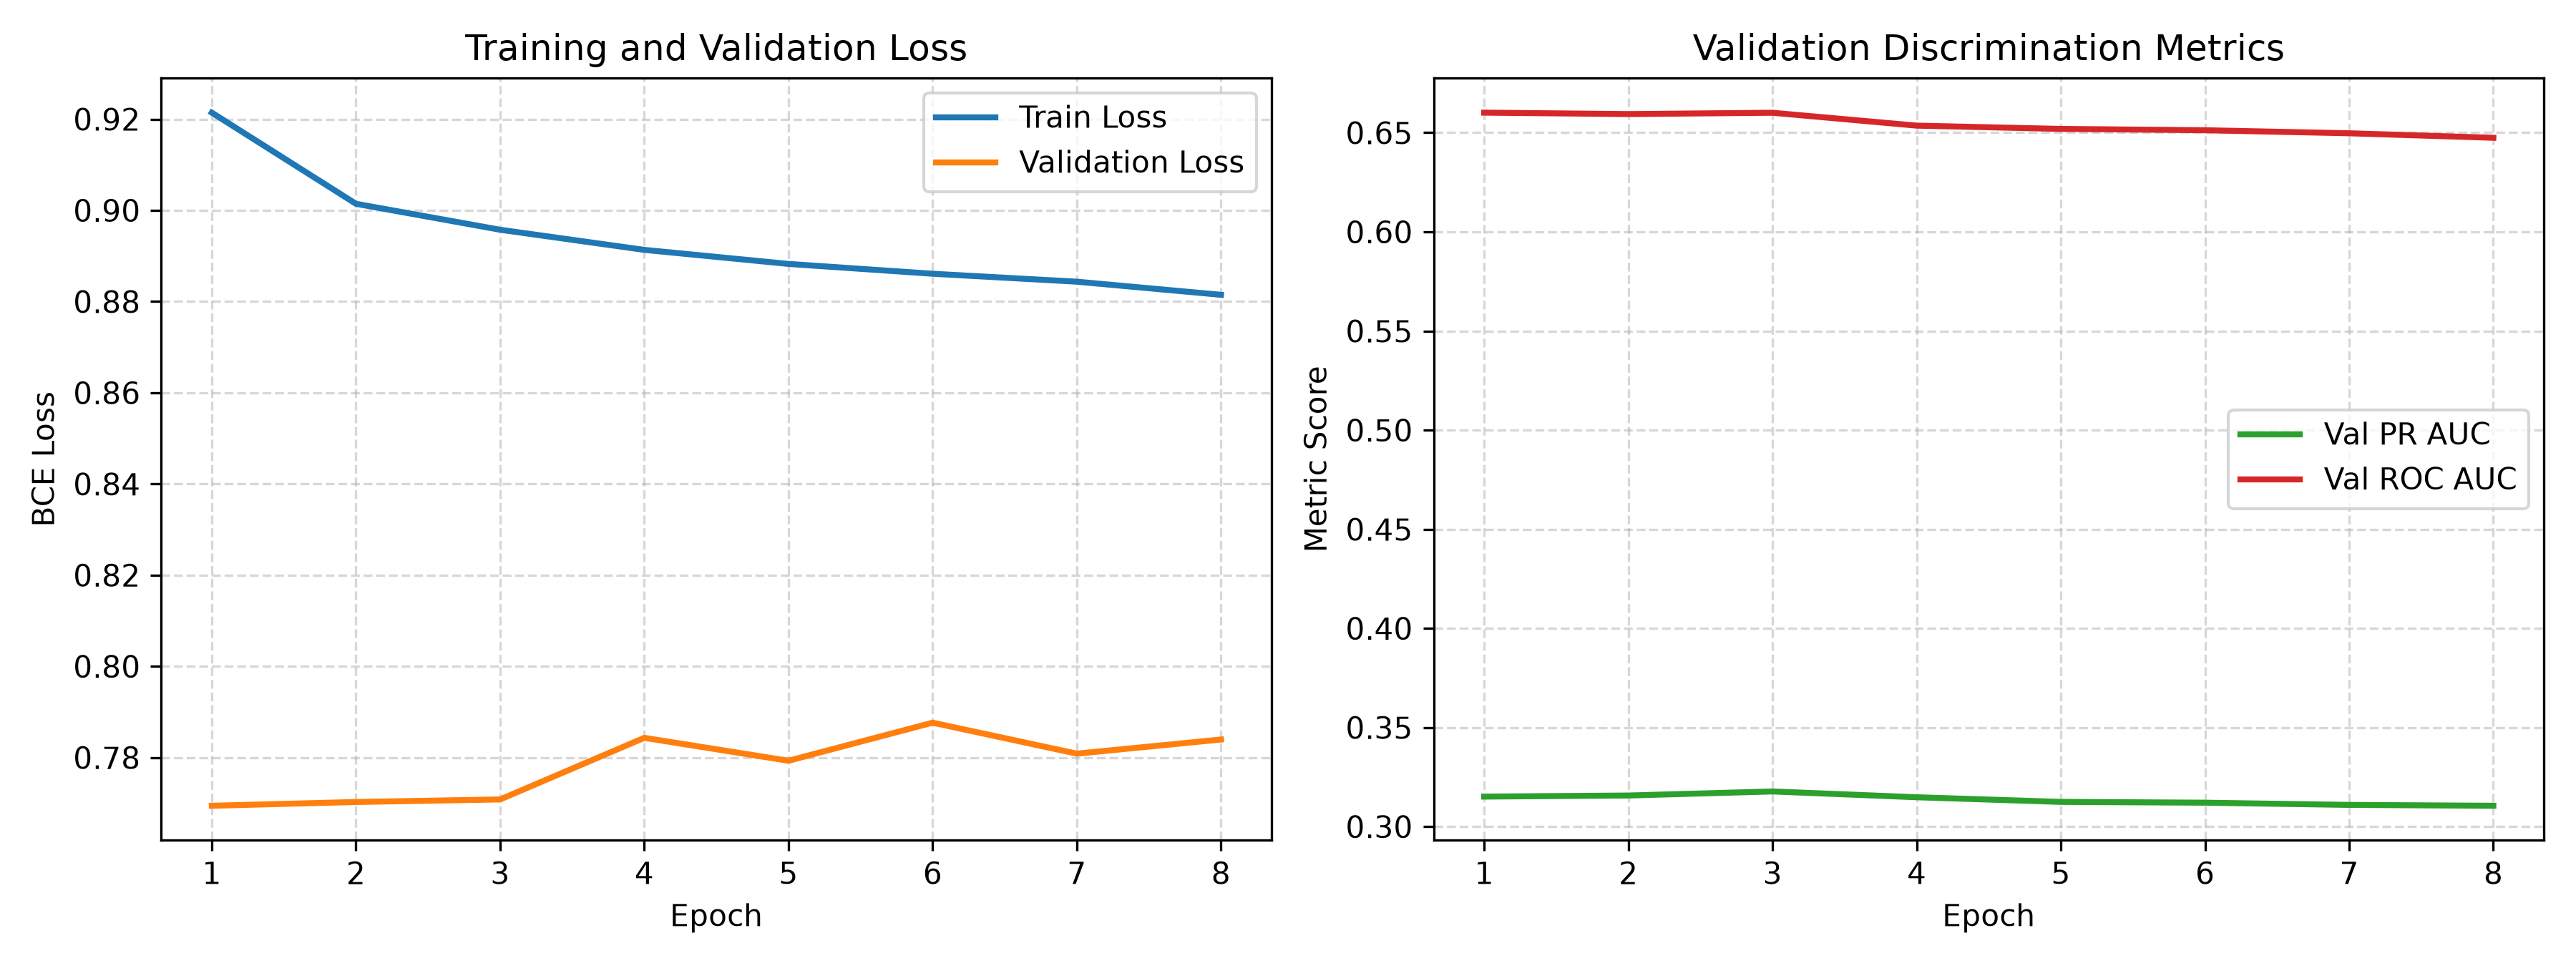

In [6]:
from src.dl_model import plot_training_curves

curve_path = plot_training_curves(history)   # saves reports/figures/dl_mlp_training_curves.png
display(Image(filename=str(curve_path), width=900))

## 6. Test the model
We choose the decision threshold **on the validation set** (so that precision is about 0.40), then use the same threshold on the test set.

In [7]:
from src.phase2_train import find_threshold_for_precision, evaluate_with_threshold

c_va, o_va, d_va, x_va = build_tensors(val_df,  artifacts["mapper"], artifacts["scaler"], PHASE2_NUMERIC_FEATURES, is_train=False)
c_te, o_te, d_te, x_te = build_tensors(test_df, artifacts["mapper"], artifacts["scaler"], PHASE2_NUMERIC_FEATURES, is_train=False)

val_probs  = model.predict_proba(c_va, o_va, d_va, x_va)
test_probs = model.predict_proba(c_te, o_te, d_te, x_te)

threshold = find_threshold_for_precision(y_val, val_probs, target_precision=0.40)
mlp_metrics = evaluate_with_threshold(y_test, test_probs, threshold)

mlp_row = {"Model": "PyTorch MLP (embeddings)", "Features": "Phase 2 (23 features)", **mlp_metrics}
pd.DataFrame([mlp_row]).round(4)

,Model,Features,threshold,pr_auc,roc_auc,precision,recall,f1,accuracy,brier_score
0,PyTorch MLP (embeddings),Phase 2 (23 features),0.4706,0.4725,0.669,0.6002,0.2347,0.3374,0.754,0.1789


## 7. Compare with the ML baselines
The baseline table is the one saved by Notebook 1. PR AUC and ROC AUC do not depend on the threshold, so they are the fairest numbers to compare.

In [8]:
metrics_dir = ROOT / "reports" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

baseline_path = metrics_dir / "phase2_baseline_comparison.csv"
if baseline_path.exists():
    comparison = pd.concat([pd.read_csv(baseline_path), pd.DataFrame([mlp_row])], ignore_index=True)
else:
    print("Baseline file not found. Run Notebook 1 first. Showing only the MLP.")
    comparison = pd.DataFrame([mlp_row])

comparison.to_csv(metrics_dir / "phase2_mlp_vs_baselines.csv", index=False)
comparison[["Model", "Features", "threshold", "pr_auc", "roc_auc",
            "precision", "recall", "f1", "brier_score"]].round(4)

,Model,Features,threshold,pr_auc,roc_auc,precision,recall,f1,brier_score
0,Logistic Regression,Phase 1 (16 features),0.7103,0.3084,0.5682,0.0000,0.0000,0.0000,0.2092
1,Logistic Regression,Phase 2 (23 features),0.4842,0.4695,0.6676,0.6453,0.1825,0.2845,0.1785
2,PyTorch MLP (embeddings),Phase 2 (23 features),0.4706,0.4725,0.6690,0.6002,0.2347,0.3374,0.1789


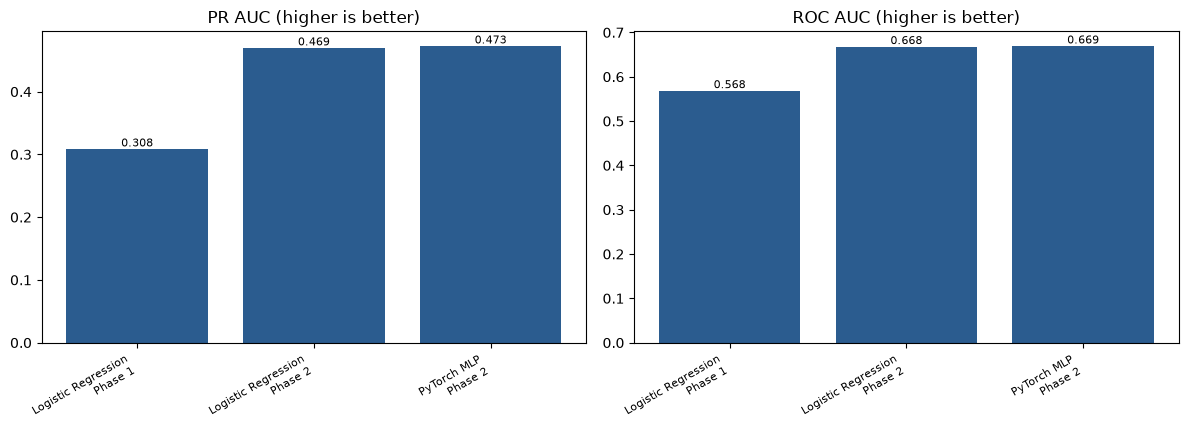

In [9]:
fig_dir = ROOT / "reports" / "figures"

plot_df = comparison.copy()
plot_df["Label"] = plot_df["Model"].str.replace(" (embeddings)", "", regex=False) + "\n" + plot_df["Features"].str.split(" ").str[0] + " " + plot_df["Features"].str.split(" ").str[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ["pr_auc", "roc_auc"], ["PR AUC (higher is better)", "ROC AUC (higher is better)"]):
    bars = ax.bar(range(len(plot_df)), plot_df[metric], color="#2b5c8f")
    ax.set_xticks(range(len(plot_df)))
    ax.set_xticklabels(plot_df["Label"], rotation=30, ha="right", fontsize=8)
    ax.set_title(title)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig(fig_dir / "phase2_mlp_vs_baselines.png", dpi=150)
plt.show()

## 8. What did the embeddings learn?
Each carrier now has 4 learned numbers. We squeeze them into 2D with PCA to draw a map. Airlines that are close on the map behave similarly for the network.

**Note:** this map is only for understanding. We do not claim that it proves anything.

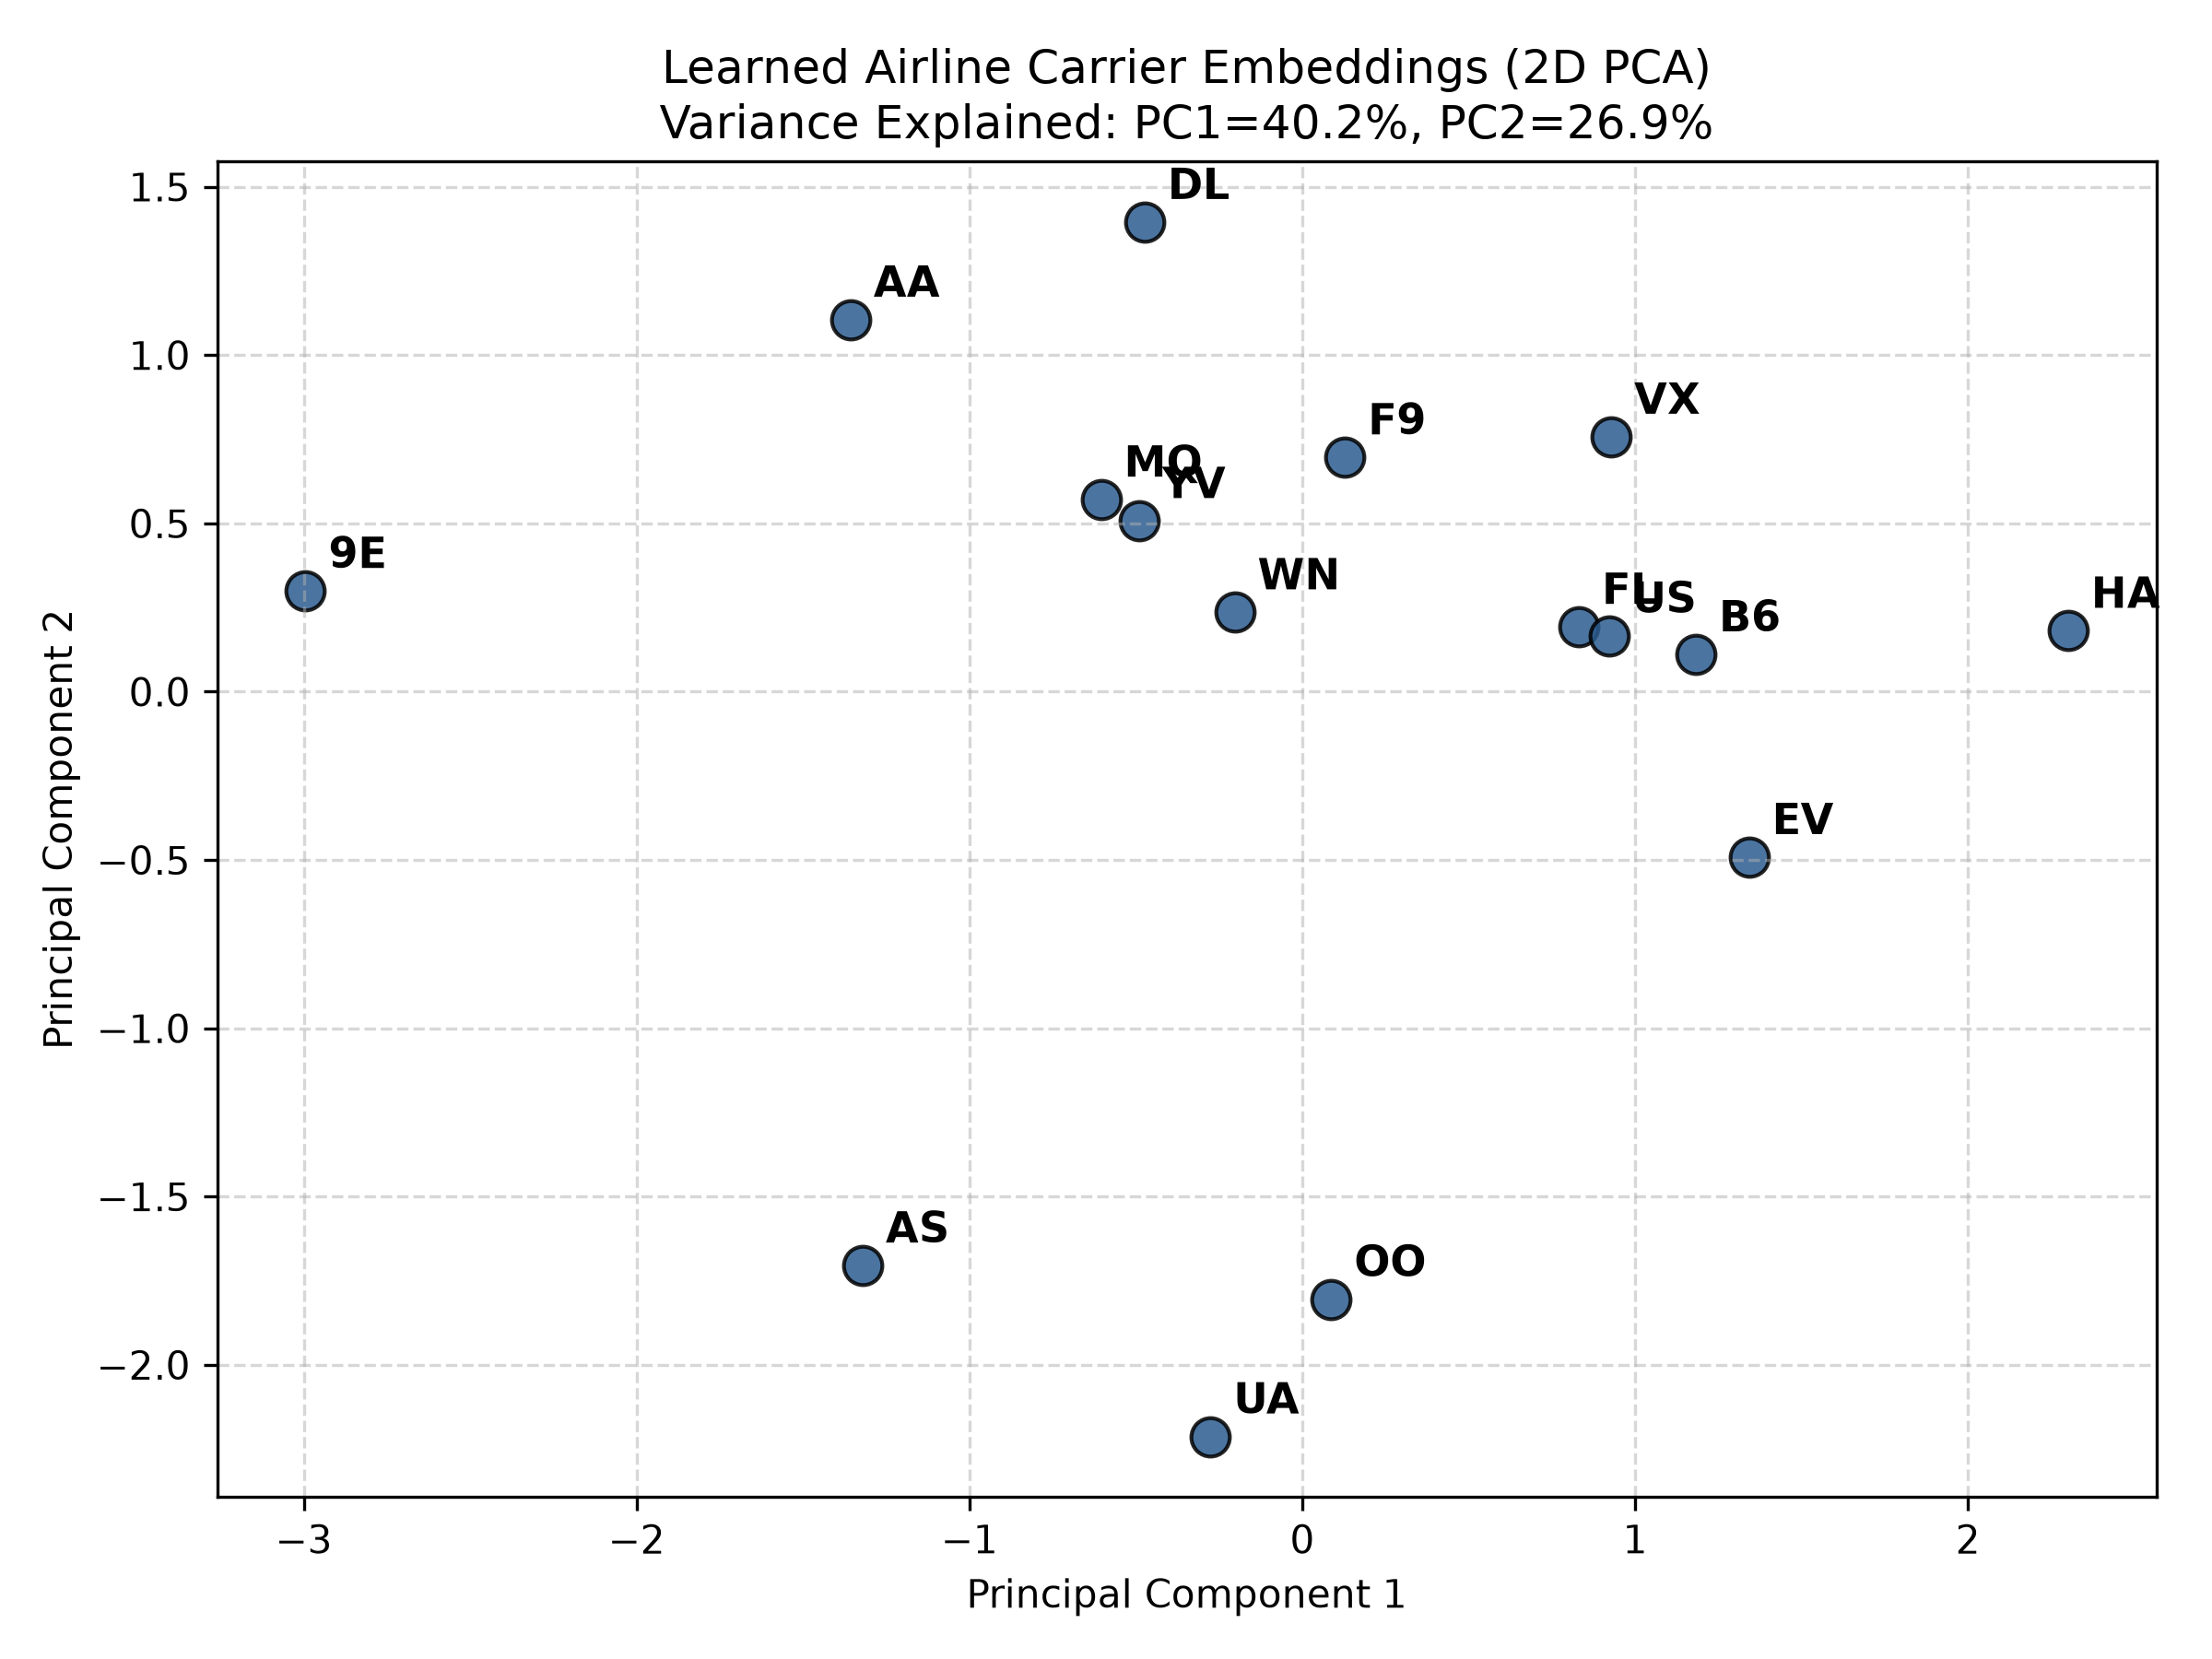

,dim_1,dim_2,dim_3,dim_4
9E,1.816,1.417,0.871,-1.999
AA,0.694,-1.174,-0.170,-1.610
AS,-0.675,1.624,-0.461,-1.495
B6,-0.704,-0.477,-0.706,0.810
DL,1.580,-0.104,-0.559,0.286
EV,-0.734,1.048,0.738,1.608
F9,1.219,1.234,0.636,1.340
FL,-0.279,0.027,-0.095,0.854
HA,-1.360,-0.883,-0.227,1.687
MQ,0.258,-0.339,0.451,-0.633


In [10]:
from src.dl_model import plot_carrier_embeddings

emb_path = plot_carrier_embeddings(model, artifacts["mapper"])   # saves reports/figures/dl_carrier_embeddings.png
display(Image(filename=str(emb_path), width=600))

carrier_map = artifacts["mapper"].mappings["carrier"]
carrier_vectors = pd.DataFrame(
    model.carrier_embed.weight.detach().numpy()[list(carrier_map.values())],
    index=list(carrier_map.keys()),
    columns=[f"dim_{i+1}" for i in range(4)],
)
carrier_vectors.round(3)

## 9. Reload check
We load the model file that is saved in `models/` and make sure it gives the same test score as the model we just trained. This shows that the saved model can be reused.

In [11]:
import joblib
from sklearn.metrics import average_precision_score

saved_artifacts = joblib.load(ROOT / "models" / "dl_artifacts.joblib")
cfg = saved_artifacts["config"]
mapper2 = saved_artifacts["mapper"]

reloaded = FlightMLP(
    num_carriers=mapper2.num_classes("carrier"),
    num_origins=mapper2.num_classes("origin"),
    num_dests=mapper2.num_classes("dest"),
    num_numeric=len(saved_artifacts["numeric_cols"]),
    carrier_dim=cfg["carrier_dim"], origin_dim=cfg["origin_dim"],
    dest_dim=cfg["dest_dim"], dropout=cfg["dropout"],
)
reloaded.load_state_dict(torch.load(ROOT / "models" / "dl_mlp_embeddings.pt"))

c2, o2, d2, x2 = build_tensors(test_df, mapper2, saved_artifacts["scaler"], saved_artifacts["numeric_cols"], is_train=False)
probs_reloaded = reloaded.predict_proba(c2, o2, d2, x2)

print("Test PR AUC (model trained now)  :", round(average_precision_score(y_test, test_probs), 4))
print("Test PR AUC (saved model on disk):", round(average_precision_score(y_test, probs_reloaded), 4))

Test PR AUC (model trained now)  : 0.4725
Test PR AUC (saved model on disk): 0.4723


## What we learned
- (We will write the real numbers here after the results are checked.)
- The network learned small embeddings for airline, origin and destination, and uses them together with the 20 numeric features.
- Dropout, weight decay, class weights and early stopping were used so the network does not memorize the training data.
- The saved model reloads correctly and gives the same score.